# 01 原子モデルと傾斜シリーズ / Atomic model and tilt series

実験では，試料を少しずつ傾けながら HAADF-STEM 像（投影像）を撮影します．これを**傾斜シリーズ**と呼びます．ここでは，原子の位置と元素がわかっている「正解」のナノ粒子モデルを作り，そのシミュレーション投影像にノイズを加えて傾斜シリーズを作ります．正解がわかっているので，後のノートブックで再構成や原子の抽出がどれだけ正しいかを確かめられます．

In an experiment, HAADF-STEM images (projections) are recorded while the specimen is tilted step by step; this is a **tilt series**. Here we build a ground-truth nanoparticle whose atomic positions and species are known, simulate its projections and add noise. Because the answer is known, the later notebooks can check how accurate the reconstruction and the atom tracing are.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # リポジトリの最上位 / repository root
sys.path.insert(0, str(ROOT / "src"))     # src/ のパッケージを使う / use the packages in src/
DATA = ROOT / "data"                      # データの保存先 / where data are saved
DATA.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100

In [2]:
from aet_tools import fcc_particle, tilt_angles, tilt_series, add_poisson_noise
from aet_tools import show_projections, show_orthoslices

## 1. 原子モデル / Atomic model

直径 3 nm の FePt 合金ナノ粒子（fcc 構造，格子定数 3.85 Å）を作ります．各サイトの元素（Fe か Pt）はランダムに決めます（不規則相）．

We build a 3 nm FePt alloy nanoparticle (fcc, lattice constant 3.85 Å). Each site is randomly occupied by Fe or Pt (chemically disordered phase).

- `n`：三次元像の箱の一辺（ピクセル） / edge length of the volume (pixels)
- `pixel_size`：1 ピクセルの大きさ（Å）．AET では 0.3〜0.4 Å 程度がよく使われます． / pixel size in Å; 0.3–0.4 Å is typical for AET.
- HAADF 像の強度は原子番号 Z のおよそ 1.7 乗に比例するとして，Fe を 1 としたときの Pt の強度を決めています．
  The HAADF intensity is taken to scale as about Z<sup>1.7</sup>, relative to Fe = 1.

In [3]:
particle = fcc_particle(n=96, pixel_size=0.4, diameter_nm=3.0,
                        names=("Fe", "Pt"), atomic_numbers=(26, 78), seed=0)
print(particle.summary())
print("relative intensity per atom:", dict(zip(particle.names, np.round(particle.amplitudes, 2))))

959 atoms (Fe 501, Pt 458), diameter about 2.9 nm, box 96^3 px (0.40 Å/px, 3.8 nm wide)
relative intensity per atom: {'Fe': np.float64(1.0), 'Pt': np.float64(6.47)}


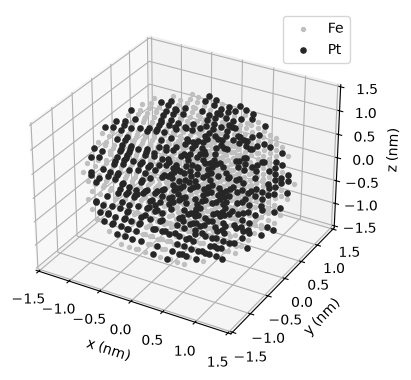

In [4]:
xyz = particle.positions * particle.pixel_size / 10        # nm
fig = plt.figure(figsize=(4.5, 4.5))
ax = fig.add_subplot(projection="3d")
for k, (name, c, s) in enumerate(zip(particle.names, ("0.75", "0.15"), (8, 14))):
    sel = particle.species == k
    ax.scatter(*xyz[sel].T, s=s, c=c, label=name, depthshade=False)
ax.set_xlabel("x (nm)"); ax.set_ylabel("y (nm)"); ax.set_zlabel("z (nm)")
ax.legend(); plt.show()

正解の三次元像（原子を小さなぼやけた球で表したもの）の断面も見ておきます．

Here are sections through the ground-truth volume, in which each atom is a small blurred sphere.

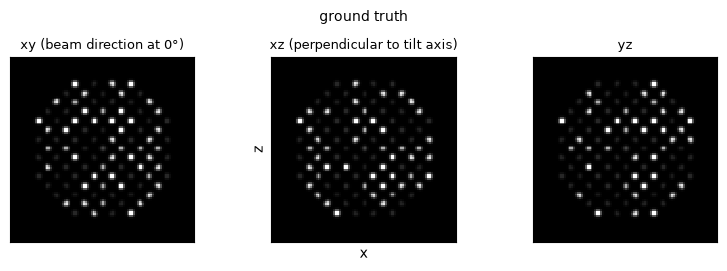

In [5]:
truth = particle.volume()
show_orthoslices(truth, "ground truth"); plt.show()

## 2. 傾斜シリーズ / Tilt series

y 軸のまわりに −70° から +70° まで 2.5° 間隔で傾けた 57 枚の投影像を計算します．実際の測定では試料ホルダーや試料の形のため ±70° 程度より大きくは傾けられないことが多く，撮れない角度の領域（**ミッシングウェッジ**）が残ります．

We compute 57 projections about the y axis from −70° to +70° in 2.5° steps. In practice the holder and the specimen usually limit the tilt to about ±70°, which leaves a range of unmeasured angles: the **missing wedge**.

57 tilts: [-70.  -67.5 -65. ] ... [65.  67.5 70. ]
projections: (96, 96, 57) (x, y, tilt index)


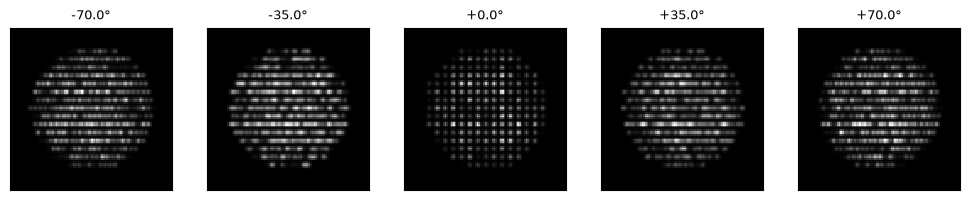

In [6]:
theta = tilt_angles(-70, 70, 2.5)
print(len(theta), "tilts:", theta[:3], "...", theta[-3:])
clean = tilt_series(particle, theta)
print("projections:", clean.shape, "(x, y, tilt index)")
show_projections(clean, theta); plt.show()

## 3. ノイズを加える / Adding noise

実際の像には，検出される電子の数のばらつき（**ポアソンノイズ**）があります．`counts_per_atom` は，Fe 原子 1 個から投影像 1 枚あたりに数えられる電子の数の目安です．小さくするほど電子線量が少なく，ノイズの多い像になります．

Real images contain **Poisson noise** from the random number of detected electrons. `counts_per_atom` is roughly the number of electrons counted per Fe atom in one projection; the smaller it is, the lower the dose and the noisier the image.

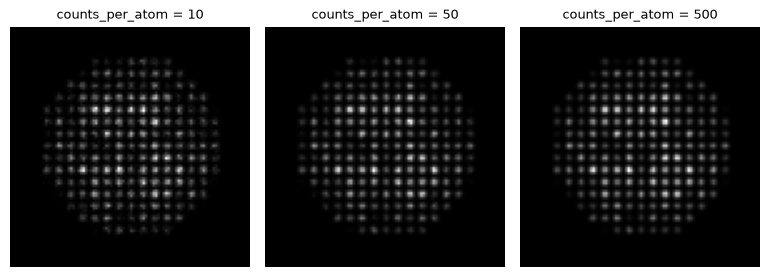

In [7]:
k = len(theta) // 2
fig, axes = plt.subplots(1, 3, figsize=(7.8, 2.8))
for ax, cpa in zip(axes, (10, 50, 500)):
    test, _ = add_poisson_noise(clean, counts_per_atom=cpa, seed=1)
    ax.imshow(test[:, :, k].T, origin="lower", cmap="gray")
    ax.set_title("counts_per_atom = %d" % cpa, fontsize=9); ax.axis("off")
fig.tight_layout(); plt.show()

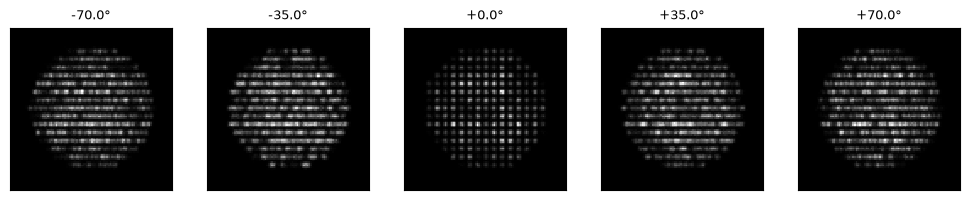

In [8]:
COUNTS_PER_ATOM = 50
projections, _ = add_poisson_noise(clean, counts_per_atom=COUNTS_PER_ATOM, seed=1)
show_projections(projections, theta); plt.show()

## 4. 保存 / Save

02 以降で使うため，投影像・傾斜角・正解の原子モデルを `data/tilt_series.npz` に保存します．

The projections, tilt angles and ground-truth model are saved to `data/tilt_series.npz` for the next notebooks.

In [9]:
np.savez_compressed(DATA / "tilt_series.npz",
                    projections=projections, theta=theta, clean=clean,
                    positions=particle.positions, species=particle.species,
                    names=np.array(particle.names), amplitudes=np.array(particle.amplitudes),
                    n=particle.n, pixel_size=particle.pixel_size)
print("saved: data/tilt_series.npz")

saved: data/tilt_series.npz


### やってみよう / Try it

- `diameter_nm=4.0`, `n=128` にして大きな粒子を作ってみましょう（02・03 の計算時間は 2〜3 倍になります）．
  Make a larger particle with `diameter_nm=4.0`, `n=128` (02 and 03 take 2–3 times longer).
- `tilt_angles(-60, 60, 2.5)` のように傾斜範囲を狭くすると，ミッシングウェッジが広がります．再構成はどう変わるでしょうか．
  Narrow the tilt range, e.g. `tilt_angles(-60, 60, 2.5)`: the missing wedge grows. How does the reconstruction change?
- `atomic_numbers=(46, 78)`（PdPt）のように原子番号の近い組み合わせにすると，元素の分類が難しくなります（04 で確かめます）．
  With elements of similar Z, e.g. `atomic_numbers=(46, 78)` (PdPt), classification gets harder (checked in 04).

値を変えたら，このノートブックを最初から実行し直し，02 以降も実行し直してください．

After changing a value, rerun this notebook from the top, then rerun 02 onwards.